# 3. Forecasting: which model predicts tomorrow's volatility best?

Five models forecast next-session log RV for EUR/USD, walk-forward with no
look-ahead. They are compared on 2025–2026 with QLIKE (on variance forecasts)
and MSE on log RV, and every benchmark is tested against HAR with a one-sided
Diebold–Mariano test.

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from rvol import experiment
from rvol.backtesting import WalkForwardPlanner, WalkForwardRunner
from rvol.evaluation import cumulative_loss_advantage

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
DAILY = ROOT / "data/derived/EURUSD_daily_rv_5min.parquet"

CALIBRATION_START = date(2024, 10, 1)  # forecasts from here only feed the smearing factor
EVALUATION_START = date(2025, 1, 1)
FORECAST_END = date(2026, 9, 30)

## Inputs

For every session: today's log RV and its 5- and 22-session means (the HAR
inputs), and the target, which is the next session's log RV.

In [2]:
daily = pd.read_parquet(DAILY)
prepared = experiment.prepare(daily)
prepared.tail()

,origin_date,target_date,log_rv_daily,log_rv_weekly,log_rv_monthly,target
946,2026-09-24,2026-09-25,-11.306519,-11.786449,-11.911645,-11.701473
947,2026-09-25,2026-09-28,-11.701473,-11.691360,-11.880244,-11.337759
948,2026-09-28,2026-09-29,-11.337759,-11.468484,-11.834205,-11.395401
949,2026-09-29,2026-09-30,-11.395401,-11.395398,-11.819418,-11.226630
950,2026-09-30,2026-10-01,-11.226630,-11.393556,-11.767709,-10.538294


## Walk-forward forecasts

Every model is refitted each session on all outcomes observed so far (at least
252 sessions). The five models:

- **historical mean** of past log RV;
- **naive**: tomorrow equals today;
- **EWMA** of past log RV (decay 0.94);
- **AR(1)** on today's log RV;
- **HAR**: regression on today's log RV and its 5- and 22-session means.

In [3]:
runner = WalkForwardRunner(
    WalkForwardPlanner(
        window="expanding",
        min_train_size=252,
        refit_every=1,
        forecast_start=CALIBRATION_START,
        forecast_end=FORECAST_END,
    )
)
forecasts = experiment.forecast(prepared, experiment.benchmark_models(), runner, run_id="eurusd")
forecasts.groupby("model").size().rename("forecasts").to_frame()

,forecasts
model,
AR1,518
EWMA,518
HAR,518
historical_mean,518
naive,518


In [4]:
pd.Series(runner.plan(prepared).execution, name="walk-forward settings").to_frame()

,walk-forward settings
method,walk_forward
window,expanding
window_size,None
min_train_size,252
refit_every,1
forecast_start,2024-10-01
forecast_end,2026-09-30
schedule_anchor,2024-01-22
observation_updates,newly_available_targets_between_refits


## Results

Log forecasts are scored with MSE on log RV. For QLIKE they are turned back into
variance: exp(log forecast) is the median of RV rather than its mean, so it is
multiplied by a Duan smearing factor, the mean of exp(error) over the model's
earlier errors observable at the forecast date.

In [5]:
comparison = experiment.compare(forecasts, evaluation_start=EVALUATION_START)
table = experiment.results_table(comparison)
table.style.format(
    {
        "QLIKE": "{:.3f}",
        "log-RV MSE": "{:.3f}",
        "QLIKE: HAR lower by": "{:.1%}",
        "log-RV MSE: HAR lower by": "{:.1%}",
        "QLIKE: DM p-value": "{:.1e}",
        "log-RV MSE: DM p-value": "{:.1e}",
        "HAR wins (QLIKE)": "{:.0%}",
    },
    na_rep="—",
)

,QLIKE,QLIKE: HAR lower by,QLIKE: DM p-value,log-RV MSE,log-RV MSE: HAR lower by,log-RV MSE: DM p-value,HAR wins (QLIKE)
model,,,,,,,
HAR,0.152,0.0%,—,0.265,0.0%,—,—
AR1,0.182,16.3%,2.4e-05,0.310,14.4%,1.2e-04,61%
EWMA,0.184,17.2%,8.1e-04,0.305,13.1%,8.9e-03,63%
naive,0.192,20.6%,2.2e-04,0.359,26.2%,5.9e-06,51%
historical_mean,0.326,53.2%,1.9e-11,0.541,50.9%,1.0e-07,76%


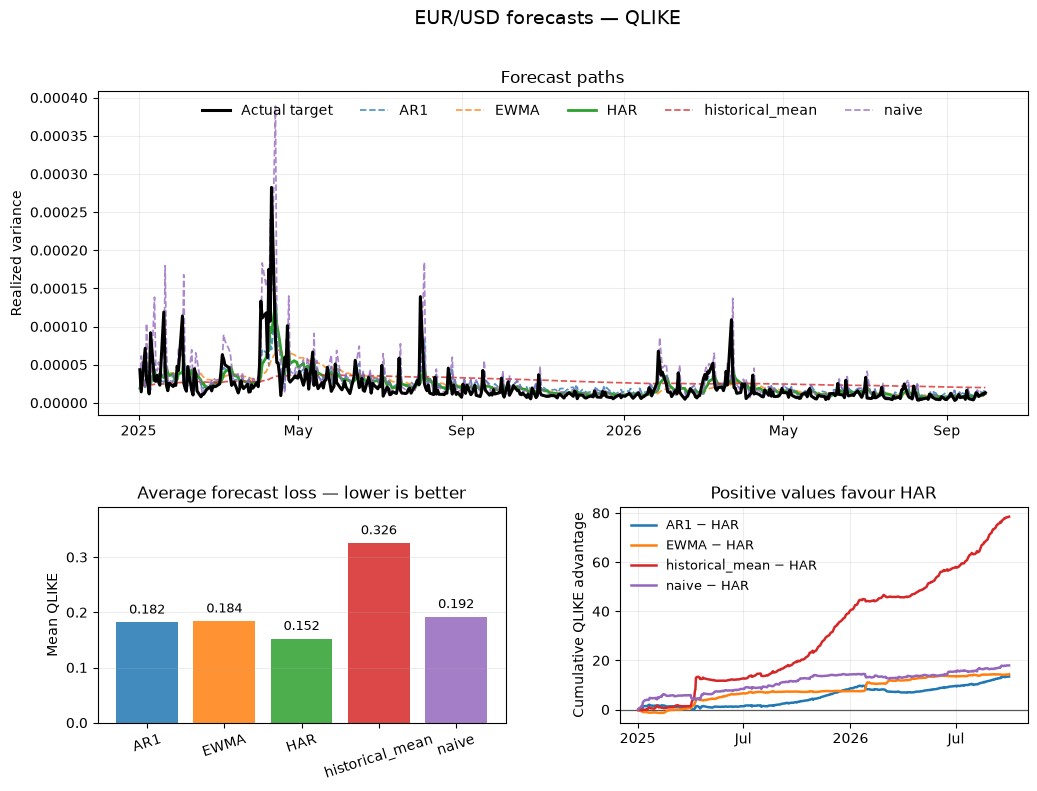

In [6]:
def draw_forecast_evaluation(scale, *, metric: str, target_label: str, title: str):
    """Forecast paths, mean loss per model and the candidate's cumulative advantage."""
    candidate = comparison.candidate
    models = sorted(scale.forecasts["model"].unique())
    colors = {name: f"C{index % 10}" for index, name in enumerate(models)}
    by_model = {name: group for name, group in scale.forecasts.groupby("model")}
    reference = by_model[candidate]
    dates = reference["target_date"].to_numpy(dtype="datetime64[D]")
    means = scale.evaluation.summaries.set_index("model")["mean_loss"].loc[models]
    advantage = cumulative_loss_advantage(scale.evaluation, metric=metric, candidate=candidate)

    figure = plt.figure(figsize=(12.0, 8.2))
    grid = figure.add_gridspec(2, 2, height_ratios=[1.5, 1], hspace=0.34, wspace=0.28)
    forecast_axis = figure.add_subplot(grid[0, :])
    loss_axis = figure.add_subplot(grid[1, 0])
    advantage_axis = figure.add_subplot(grid[1, 1])

    forecast_axis.plot(dates, reference["actual"], color="black", linewidth=2.2,
                       label="Actual target", zorder=5)
    for name in models:
        forecast_axis.plot(
            dates, by_model[name]["predicted"], color=colors[name],
            linestyle="-" if name == candidate else "--",
            linewidth=2 if name == candidate else 1.25,
            alpha=1 if name == candidate else 0.78, label=name,
        )
    locator = mdates.AutoDateLocator(minticks=4, maxticks=8)
    forecast_axis.xaxis.set_major_locator(locator)
    forecast_axis.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator, show_offset=False)
    )
    forecast_axis.set_ylabel(target_label)
    forecast_axis.set_title("Forecast paths")
    forecast_axis.grid(alpha=0.22)
    forecast_axis.legend(frameon=False, ncols=len(models) + 1, loc="upper center")

    bars = loss_axis.bar(models, means.to_numpy(), color=[colors[name] for name in models],
                         alpha=0.85)
    loss_axis.set_ylabel(f"Mean {metric}")
    loss_axis.set_title("Average forecast loss — lower is better")
    loss_axis.grid(axis="y", alpha=0.22)
    loss_axis.tick_params(axis="x", rotation=18)
    loss_axis.set_ylim(0, float(means.max()) * 1.2)
    for bar, value in zip(bars, means, strict=True):
        loss_axis.annotate(f"{value:.3f}", xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                           xytext=(0, 4), textcoords="offset points", ha="center", va="bottom",
                           fontsize=9)

    advantage_axis.axhline(0, color="0.35", linewidth=0.9)
    for baseline in advantage.columns:
        advantage_axis.plot(dates, advantage[baseline].to_numpy(), color=colors[baseline],
                            linewidth=1.8, label=f"{baseline} − {candidate}")
    locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
    advantage_axis.xaxis.set_major_locator(locator)
    advantage_axis.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator, show_offset=False)
    )
    advantage_axis.set_ylabel(f"Cumulative {metric} advantage")
    advantage_axis.set_title(f"Positive values favour {candidate}")
    advantage_axis.grid(alpha=0.22)
    advantage_axis.legend(frameon=False, fontsize=9)
    figure.suptitle(title, fontsize=14)
    return figure


fig = draw_forecast_evaluation(
    comparison.variance, metric="QLIKE", target_label="Realized variance",
    title="EUR/USD forecasts — QLIKE",
)
fig.savefig(FIGURES / "eurusd_forecasts.png", dpi=160, bbox_inches="tight")

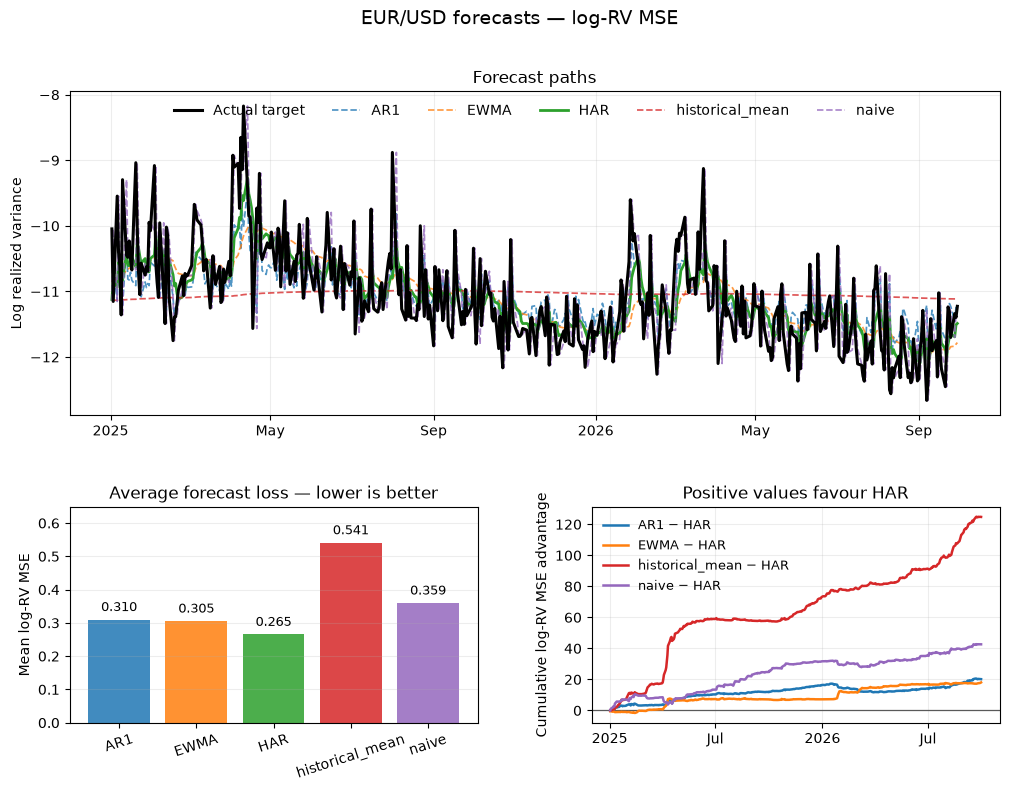

In [7]:
draw_forecast_evaluation(
    comparison.log_rv, metric="log-RV MSE", target_label="Log realized variance",
    title="EUR/USD forecasts — log-RV MSE",
);

## Robustness

Does the conclusion depend on the number of Newey–West lags in the DM test?

In [8]:
comparison.variance.robustness["hac_sensitivity"].pivot(
    index="hac_lags", columns="baseline_model", values="p_value"
)

baseline_model,AR1,EWMA,historical_mean,naive
hac_lags,,,,
0,0.000012,0.000001,3.644130e-26,0.000196
1,0.000011,0.000040,2.755754e-19,0.000198
2,0.000015,0.000198,1.368862e-15,0.000185
3,0.000018,0.000410,1.017706e-13,0.000195
4,0.000021,0.000635,2.252788e-12,0.000207
5,0.000024,0.000810,1.905059e-11,0.000225


Is HAR's advantage spread over the sample or concentrated in a few months?

In [9]:
comparison.variance.robustness["monthly_losses"].pivot(
    index="month", columns="model", values="mean_loss"
).style.highlight_min(axis=1).format("{:.3f}")

model,AR1,EWMA,HAR,historical_mean,naive
month,,,,,
2025-01,0.330,0.205,0.259,0.285,0.474
2025-02,0.203,0.267,0.214,0.234,0.267
2025-03,0.056,0.121,0.087,0.106,0.088
2025-04,0.329,0.469,0.313,0.813,0.334
2025-05,0.123,0.180,0.117,0.086,0.185
2025-06,0.104,0.151,0.096,0.136,0.124
2025-07,0.152,0.163,0.137,0.228,0.163
2025-08,0.295,0.286,0.284,0.339,0.345
2025-09,0.162,0.124,0.114,0.283,0.170


The smearing factor applied to each model's variance forecasts:

In [10]:
comparison.variance.forecasts.groupby("model")["smearing_factor"].describe()[["mean", "min", "max"]]

,mean,min,max
model,,,
AR1,1.403864,1.204567,1.622614
EWMA,1.286547,1.185661,1.506626
HAR,1.255572,1.168538,1.401392
historical_mean,1.729656,1.341732,2.224666
naive,1.301923,1.229965,1.510625


## Conclusion

HAR has the lowest loss under both metrics and beats every benchmark at the 1%
level, by 16–53% in QLIKE. Its advantage over the naive forecast comes from
avoiding large misses rather than winning every day: it wins only about half of
the sessions but has a much lower mean loss.

Limitations: one instrument and one period; AR(1) is nested in HAR, so its DM
test is approximate (and conservative); models are fitted by least squares on
logs but scored by QLIKE on variance.